# Vehicle Price Estimation — Model Training

This notebook trains a **used-vehicle price estimation model** on a synthetic dataset
("cote" — quote/valuation) and exports a self-contained inference artifact
(preprocessing + model bundled in a single `sklearn.Pipeline`) that a downstream
**inference API** can load and call directly with raw request data.

**Target column:** `price`

**Raw input features:**
| column | type | notes |
|---|---|---|
| `brand` | categorical | one of `ford`, `audi`, `bmw`, `tesla` |
| `date_first_circulation` | date | first registration date; converted to `age_years` during preprocessing |
| `km` | numeric | odometer reading |
| `gearbox` | categorical | `manual` or `auto` |

**Key modelling requirement:** the model must be **monotonic** in `age_years` and `km`
— all else equal, an older or more-driven car must never be predicted as *more*
expensive. This is enforced with XGBoost's native `monotone_constraints`, not just
hoped for from the data.

**Design choice for the API team:** the date → age conversion and all categorical
encoding are implemented as part of the saved `Pipeline`, *not* as a separate
preprocessing script. The inference API should only need to load the pipeline and
call `.predict()` on a small DataFrame built from the request payload — it must not
re-implement feature engineering.


## 1. Imports & configuration

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

In [ ]:
# Feature contract shared by the data generator, the preprocessing pipeline and
# the metadata exported for the API. Order matters for `BRANDS` and `GEARBOXES`
# below: it fixes the column order produced by the encoders and therefore the
# order of the `monotone_constraints` tuple later on.
BRANDS = ["audi", "bmw", "ford", "tesla"]
GEARBOXES = ["manual", "auto"]

DATE_COLUMN = "date_first_circulation"
AGE_COLUMN = "age_years"
TARGET_COLUMN = "price"

ARTIFACTS_DIR = Path("artifacts")
DATA_DIR = Path("data")
ARTIFACTS_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)

## 2. Synthetic dataset generation

We simulate a plausible used-car market:

- Each `brand` has its own approximate new-car base price and market share.
- `date_first_circulation` gives a car age between 0 and ~15 years.
- `km` grows with age (with noise) — older cars tend to have driven more, but not deterministically.
- `price` decays **exponentially with age and km** (classic depreciation curves), gets a small
  premium for automatic gearboxes, and has multiplicative gaussian noise on top.
- Tesla is generated as **always automatic** (no manual Tesla exists), which is a realistic
  categorical/gearbox interaction the model does *not* need to be monotonic about.

This is synthetic data built to have a believable signal — it is not meant to reflect real
market prices.


In [ ]:
N_SAMPLES = 8_000

BASE_PRICE = {"ford": 18_000, "audi": 32_000, "bmw": 35_000, "tesla": 42_000}
brand_SHARE = {"ford": 0.35, "audi": 0.25, "bmw": 0.25, "tesla": 0.15}


def generate_synthetic_dataset(n_samples: int, seed: int) -> pd.DataFrame:
    """Generate a synthetic used-vehicle dataset with a realistic depreciation signal."""
    generator = np.random.default_rng(seed)
    today = pd.Timestamp.now().normalize()

    brand = generator.choice(
        list(brand_SHARE.keys()), size=n_samples, p=list(brand_SHARE.values())
    )

    age_years = generator.uniform(0, 15, size=n_samples)
    date_first_circulation = today - pd.to_timedelta(age_years * 365.25, unit="D")

    # Tesla never comes with a manual gearbox.
    gearbox = np.where(
        brand == "tesla",
        "auto",
        generator.choice(GEARBOXES, size=n_samples, p=[0.6, 0.4]),
    )

    annual_km = generator.normal(13_000, 3_000, size=n_samples).clip(min=4_000)
    km = (age_years * annual_km + generator.normal(0, 4_000, size=n_samples)).clip(
        min=0
    )

    base_price = np.array([BASE_PRICE[m] for m in brand])
    age_decay = np.exp(-0.11 * age_years)
    km_decay = np.exp(-6e-6 * km)
    gearbox_premium = np.where(gearbox == "auto", 1.04, 1.0)
    noise = generator.normal(1.0, 0.06, size=n_samples)

    price = base_price * age_decay * km_decay * gearbox_premium * noise
    price = price.clip(min=800).round(-1)

    return pd.DataFrame(
        {
            "brand": brand,
            DATE_COLUMN: date_first_circulation.strftime("%Y-%m-%d"),
            "km": km.round().astype(int),
            "gearbox": gearbox,
            TARGET_COLUMN: price,
        }
    )


df = generate_synthetic_dataset(N_SAMPLES, RANDOM_SEED)
df.head()

,marque,date_first_circulation,km,gearbox,price
0,bmw,2018-03-01,108946,auto,8340.0
1,audi,2013-02-01,183303,manual,2200.0
2,tesla,2022-05-20,45519,auto,20870.0
3,bmw,2026-03-01,1807,manual,31260.0
4,ford,2014-12-02,173506,manual,1550.0


In [4]:
raw_path = DATA_DIR / "vehicles_synthetic.csv"
df.to_csv(raw_path, index=False)
print(f"Saved {len(df):,} rows to {raw_path}")

Saved 8,000 rows to data/vehicles_synthetic.csv


## 3. Exploratory data analysis

In [5]:
df.info()
df.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   marque                  8000 non-null   object 
 1   date_first_circulation  8000 non-null   object 
 2   km                      8000 non-null   int64  
 3   gearbox                 8000 non-null   object 
 4   price                   8000 non-null   float64
dtypes: float64(1), int64(1), object(3)
memory usage: 312.6+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
marque,8000,4,ford,2862,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_first_circulation,8000,4173,2016-09-20,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
km,8000.0,NaN,NaN,NaN,98085.42225,62107.847248,0.0,46286.25,92906.5,143103.25,337760.0
gearbox,8000,2,manual,4055,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,8000.0,NaN,NaN,NaN,9943.20875,8631.928191,800.0,3430.0,6890.0,13960.0,45750.0


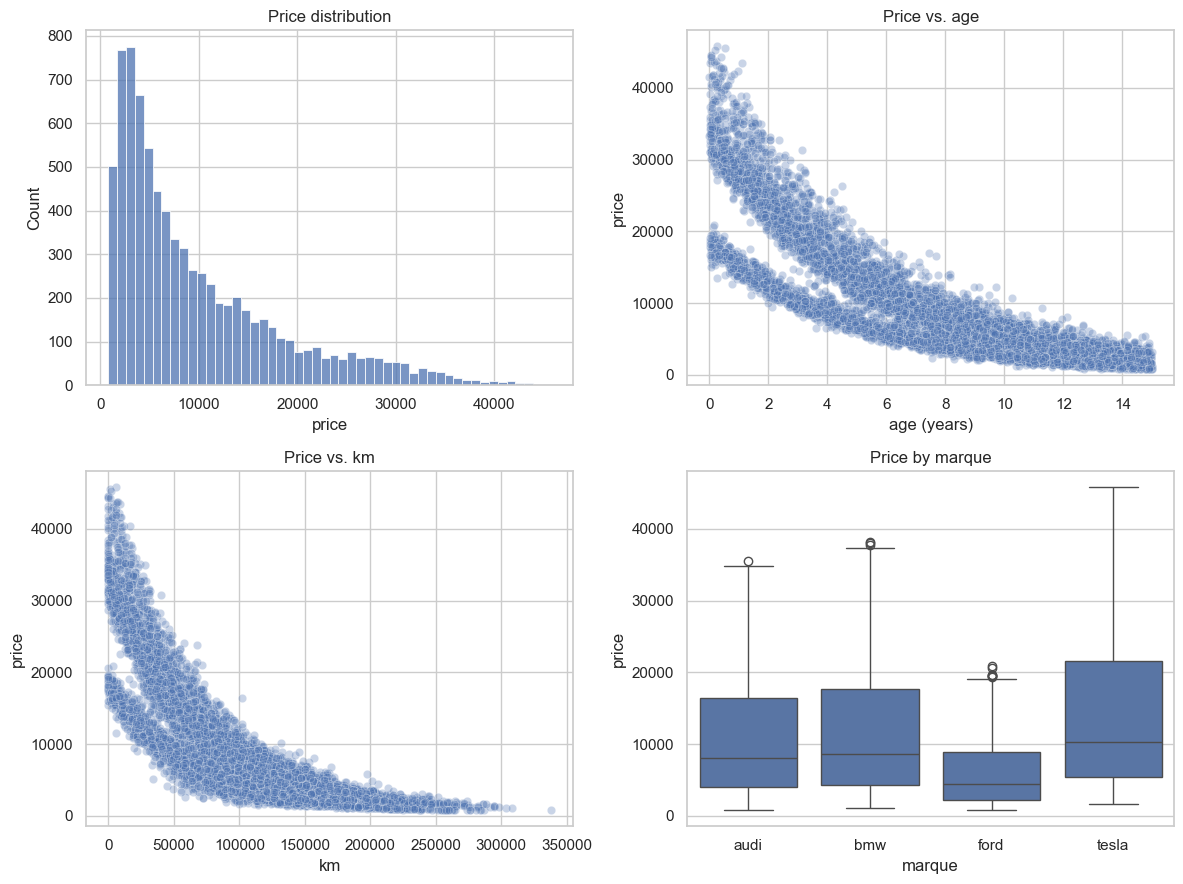

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.histplot(df[TARGET_COLUMN], bins=50, ax=axes[0, 0])
axes[0, 0].set_title("Price distribution")

age_years_preview = (
    pd.Timestamp.now().normalize() - pd.to_datetime(df[DATE_COLUMN])
).dt.days / 365.25
sns.scatterplot(x=age_years_preview, y=df[TARGET_COLUMN], alpha=0.3, ax=axes[0, 1])
axes[0, 1].set_xlabel("age (years)")
axes[0, 1].set_title("Price vs. age")

sns.scatterplot(x=df["km"], y=df[TARGET_COLUMN], alpha=0.3, ax=axes[1, 0])
axes[1, 0].set_title("Price vs. km")

sns.boxplot(x="brand", y=TARGET_COLUMN, data=df, order=BRANDS, ax=axes[1, 1])
axes[1, 1].set_title("Price by brand")

plt.tight_layout()
plt.show()

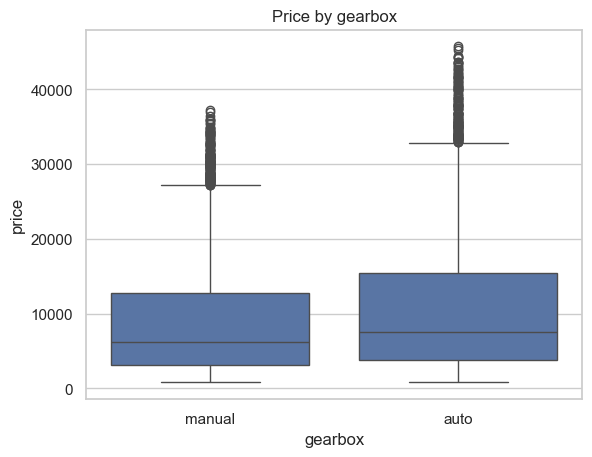

In [7]:
sns.boxplot(x="gearbox", y=TARGET_COLUMN, data=df, order=GEARBOXES)
plt.title("Price by gearbox")
plt.show()

## 4. Train / validation / test split

We hold out a validation set for XGBoost early stopping and a separate test set for the
final, unbiased evaluation. Splits are stratified on `brand` so all three sets keep the
same brand mix.


In [ ]:
X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_SEED, stratify=X["brand"]
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_SEED, stratify=X_temp["brand"]
)

print(f"train={len(X_train)}  val={len(X_val)}  test={len(X_test)}")

train=5600  val=1200  test=1200


## 5. Preprocessing

Two things happen here, both packaged as `sklearn` transformers so they end up inside the
exported `Pipeline`:

1. **`AgeFromCirculationDate`** — a custom transformer that derives `age_years` from
   `date_first_circulation`. It computes age **relative to "now" at the time `transform`
   is called**, not relative to a fixed date captured during training. This matters: a car's
   age keeps increasing after the model is trained, so the inference API must recompute it
   on every request rather than reusing a training-time constant.
2. A `ColumnTransformer` that one-hot encodes `brand`, ordinal-encodes `gearbox`
   (`manual=0`, `auto=1`) and passes `age_years` / `km` through unchanged.

The category lists (`BRANDS`, `GEARBOXES`) are passed explicitly to the encoders so the
output column order is fixed and reproducible — this is what lets us line up
`monotone_constraints` with the right columns below.


In [9]:
class AgeFromCirculationDate(BaseEstimator, TransformerMixin):
    """Derive `age_years` from a first-circulation date, relative to the current date."""

    def __init__(self, date_column: str = DATE_COLUMN, age_column: str = AGE_COLUMN):
        self.date_column = date_column
        self.age_column = age_column

    def fit(self, X: pd.DataFrame, y=None):
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        X = X.copy()
        reference_date = pd.Timestamp.now().normalize()
        dates = pd.to_datetime(X[self.date_column])
        X[self.age_column] = (reference_date - dates).dt.days / 365.25
        return X.drop(columns=[self.date_column])

In [ ]:
NUMERIC_FEATURES = [AGE_COLUMN, "km"]

column_transformer = ColumnTransformer(
    transformers=[
        (
            "brand",
            OneHotEncoder(
                categories=[BRANDS], handle_unknown="ignore", sparse_output=False
            ),
            ["brand"],
        ),
        (
            "gearbox",
            OrdinalEncoder(categories=[GEARBOXES]),
            ["gearbox"],
        ),
        ("numeric", "passthrough", NUMERIC_FEATURES),
    ]
)

preprocessing_pipeline = Pipeline(
    steps=[
        ("age_from_date", AgeFromCirculationDate()),
        ("encode", column_transformer),
    ]
)

feature_names = [f"marque_{m}" for m in BRANDS] + ["gearbox_auto"] + NUMERIC_FEATURES
feature_names

['marque_audi',
 'marque_bmw',
 'marque_ford',
 'marque_tesla',
 'gearbox_auto',
 'age_years',
 'km']

## 6. Monotonic constraints

`monotone_constraints` is a tuple aligned 1:1 with the encoded feature columns:

- `marque_*` (one-hot, unordered category) → **0**, no constraint.
- `gearbox_auto` (unordered category) → **0**, no constraint.
- `age_years` → **-1**, price must be non-increasing as age grows.
- `km` → **-1**, price must be non-increasing as mileage grows.

Building the tuple from `BRANDS`/`GEARBOXES` instead of hard-coding its length keeps it in
sync if a brand is ever added or removed.


In [ ]:
monotone_constraints = tuple([0] * len(BRANDS) + [0] + [-1, -1])
assert len(monotone_constraints) == len(feature_names)
dict(zip(feature_names, monotone_constraints))

{'marque_audi': 0,
 'marque_bmw': 0,
 'marque_ford': 0,
 'marque_tesla': 0,
 'gearbox_auto': 0,
 'age_years': -1,
 'km': -1}

## 7. Model training

XGBoost's sklearn API needs the *encoded* validation set for early stopping, so we
fit the preprocessing pipeline once and reuse its (fitted) transform for train/val/test,
then fit the regressor with `eval_set`. Afterwards we reassemble a single fitted
`Pipeline` (preprocessing + model) for export — no `.fit()` is called on it again, it is
simply the two already-fitted pieces stitched together for a clean `predict()` interface.


In [12]:
X_train_enc = preprocessing_pipeline.fit_transform(X_train)
X_val_enc = preprocessing_pipeline.transform(X_val)
X_test_enc = preprocessing_pipeline.transform(X_test)

model = XGBRegressor(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    monotone_constraints=monotone_constraints,
    early_stopping_rounds=30,
    eval_metric="mae",
    random_state=RANDOM_SEED,
    n_jobs=-1,
)

model.fit(
    X_train_enc,
    y_train,
    eval_set=[(X_train_enc, y_train), (X_val_enc, y_val)],
    verbose=False,
)

print(f"Best iteration: {model.best_iteration}")

Best iteration: 123


In [13]:
full_pipeline = Pipeline(steps=preprocessing_pipeline.steps + [("model", model)])

## 8. Evaluation

In [14]:
def regression_report(y_true, y_pred) -> dict:
    return {
        "mae": mean_absolute_error(y_true, y_pred),
        "rmse": mean_squared_error(y_true, y_pred) ** 0.5,
        "mape": mean_absolute_percentage_error(y_true, y_pred),
        "r2": r2_score(y_true, y_pred),
    }


y_pred_test = model.predict(X_test_enc)
test_metrics = regression_report(y_test, y_pred_test)
test_metrics

{'mae': 534.4914449564616,
 'rmse': 813.5174098294661,
 'mape': 0.06307943115862612,
 'r2': 0.9911601658842327}

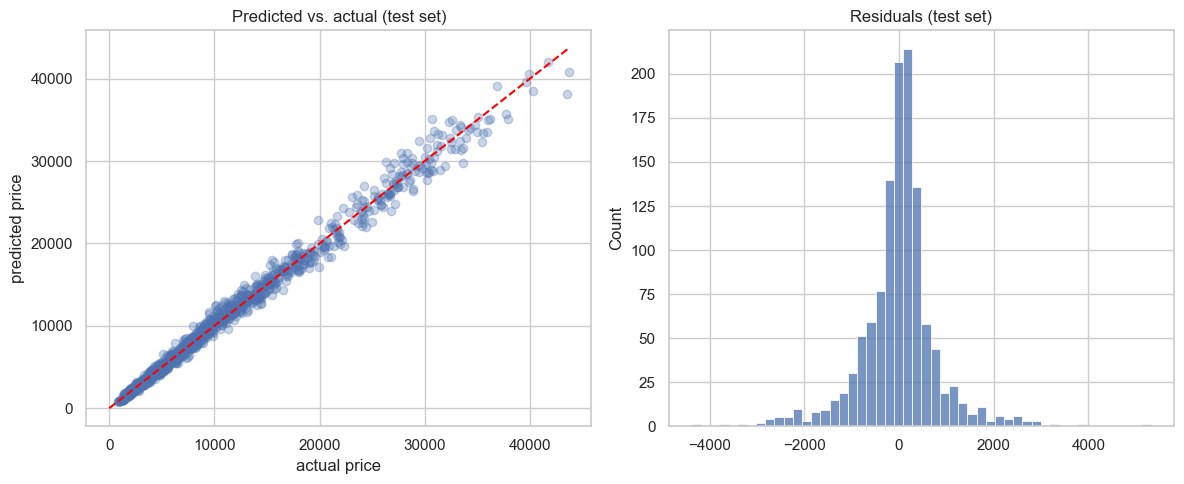

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, y_pred_test, alpha=0.3)
lims = [0, max(y_test.max(), y_pred_test.max())]
axes[0].plot(lims, lims, color="red", linestyle="--")
axes[0].set_xlabel("actual price")
axes[0].set_ylabel("predicted price")
axes[0].set_title("Predicted vs. actual (test set)")

residuals = y_test.values - y_pred_test
sns.histplot(residuals, bins=50, ax=axes[1])
axes[1].set_title("Residuals (test set)")

plt.tight_layout()
plt.show()

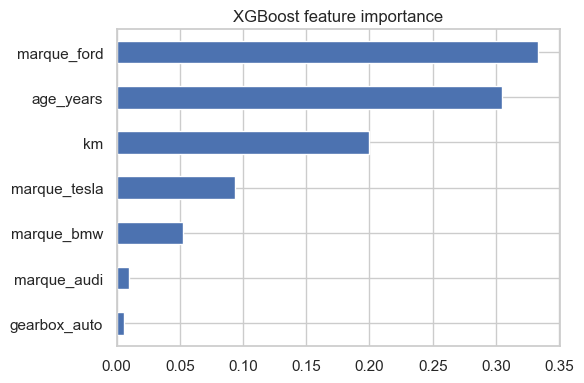

In [16]:
importances = pd.Series(model.feature_importances_, index=feature_names).sort_values()
importances.plot.barh(figsize=(6, 4), title="XGBoost feature importance")
plt.tight_layout()
plt.show()

## 9. Sanity-check the monotonic constraints

This is hard to unit-test meaningfully from raw metrics, but easy to eyeball: hold every
feature fixed except one, sweep it across its range, and confirm the predicted price curve
never goes up as age or km increase.


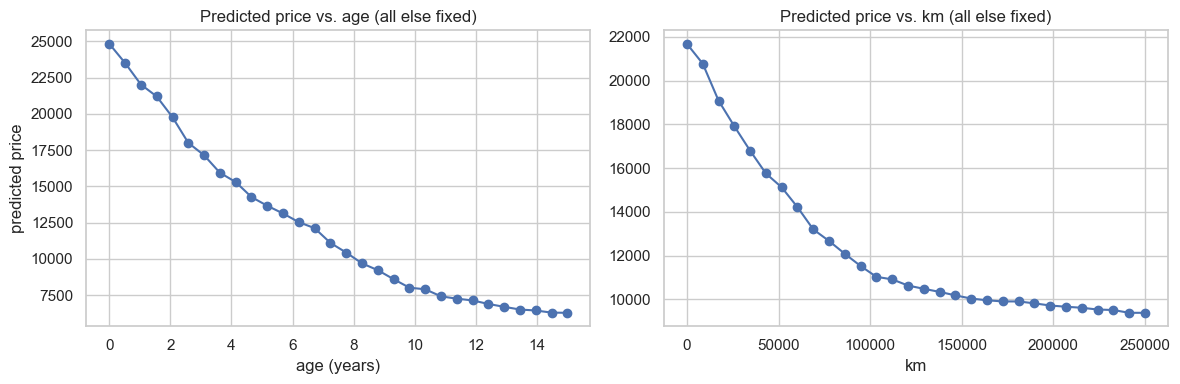

Monotonicity check passed: price is non-increasing in both age and km.


In [ ]:
def sweep_prediction(fixed: dict, sweep_column: str, values) -> pd.Series:
    rows = []
    for value in values:
        row = dict(fixed)
        row[sweep_column] = value
        rows.append(row)
    frame = pd.DataFrame(rows)
    return pd.Series(full_pipeline.predict(frame), index=values)


today = pd.Timestamp.now().normalize()

age_sweep_years = np.linspace(0, 15, 30)
fixed_for_age = {
    "brand": "bmw",
    "gearbox": "manual",
    "km": 60_000,
}
age_dates = [
    (today - pd.Timedelta(days=y * 365.25)).strftime("%Y-%m-%d")
    for y in age_sweep_years
]
price_vs_age = sweep_prediction(
    {**fixed_for_age, DATE_COLUMN: None}, DATE_COLUMN, age_dates
)
price_vs_age.index = age_sweep_years

km_sweep = np.linspace(0, 250_000, 30)
fixed_for_km = {
    "brand": "bmw",
    "gearbox": "manual",
    DATE_COLUMN: (today - pd.Timedelta(days=5 * 365.25)).strftime("%Y-%m-%d"),
}
price_vs_km = sweep_prediction(fixed_for_km, "km", km_sweep)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(price_vs_age.index, price_vs_age.values, marker="o")
axes[0].set_xlabel("age (years)")
axes[0].set_ylabel("predicted price")
axes[0].set_title("Predicted price vs. age (all else fixed)")

axes[1].plot(price_vs_km.index, price_vs_km.values, marker="o")
axes[1].set_xlabel("km")
axes[1].set_title("Predicted price vs. km (all else fixed)")

plt.tight_layout()
plt.show()

assert (price_vs_age.diff().dropna() <= 1e-6).all(), "price must not increase with age"
assert (price_vs_km.diff().dropna() <= 1e-6).all(), "price must not increase with km"
print("Monotonicity check passed: price is non-increasing in both age and km.")

## 10. Export artifacts for the inference API

Two files are produced:

- `artifacts/model_pipeline.joblib` — the full fitted `Pipeline`
  (date→age + encoding + XGBoost model). The API loads this single object and calls
  `.predict()` on a one-row DataFrame built from the request body.
- `artifacts/metadata.json` — the feature contract (allowed categorical values, required
  fields, model version, training metrics) the API can use for request validation and to
  expose on a `/model-info` type endpoint.


In [ ]:
model_path = ARTIFACTS_DIR / "model_pipeline.joblib"
joblib.dump(full_pipeline, model_path)

metadata = {
    "model_version": "1.0.0",
    "trained_at": pd.Timestamp.now().isoformat(),
    "target": TARGET_COLUMN,
    "features": {
        "brand": {"type": "categorical", "allowed_values": BRANDS},
        DATE_COLUMN: {"type": "date", "format": "YYYY-MM-DD"},
        "km": {"type": "numeric", "minimum": 0},
        "gearbox": {"type": "categorical", "allowed_values": GEARBOXES},
    },
    "monotone_constraints": dict(zip(feature_names, monotone_constraints)),
    "test_metrics": test_metrics,
}

metadata_path = ARTIFACTS_DIR / "metadata.json"
with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)

print(f"Saved model to {model_path}")
print(f"Saved metadata to {metadata_path}")

Saved model to artifacts/model_pipeline.joblib
Saved metadata to artifacts/metadata.json


In [19]:
# Reload sanity check: the artifact must be usable standalone, exactly like the API will use it.
reloaded_pipeline = joblib.load(model_path)
sample_request = pd.DataFrame(
    [{"marque": "audi", DATE_COLUMN: "2019-03-15", "km": 72_000, "gearbox": "auto"}]
)
reloaded_pipeline.predict(sample_request)

array([9647.802], dtype=float32)

## Next step

The saved `artifacts/model_pipeline.joblib` and `artifacts/metadata.json` are the only
two files the inference API needs. See the accompanying test brief for the API
requirements.
